# A3: Uncertainty for TGLF surrogates

We are asking how much we should trust a fast model that approximates TGLF,
the reference simulation. Our model uses **15 neural networks** to predict
ion heat flux ($Q_i$), electron heat flux ($Q_e$), and electron particle flux ($\Gamma_e$).
We assess its accuracy against TGLF's answers.

<a id="contents"></a>
## Contents

Click a section to jump to it. Each section explains the purpose before the code,
with one simple figure and an interpretive caption for each analysis section.
Detailed statistics appear in expandable tables below the figures.
PNG and SVG copies of the five figures are saved in `A3/figures/`.

| Section | What we are trying to learn |
|---|---|
| [Setup](#setup) | Load the networks and reuse the A2 data split. |
| [Step 1: Give each prediction an error bar](#step-1) | How uncertain is the model about its answer? |
| [Step 2: Check the error bars](#step-2) | Do they contain the TGLF answers about 90% of the time? |
| [Step 3: Try unfamiliar inputs](#step-3) | Does the model warn us when we leave its training range? |
| [Step 4: Vary uncertain measurements](#step-4) | How much do uncertain inputs change the predicted fluxes? |
| [Step 4b: Vary one input at a time](#step-4b) | Which input's measurement uncertainty matters most? |
| [Mentor discussion](#mentor-discussion) | What did we learn, and what should we investigate next? |

<a id="setup"></a>
## Setup

Select **Python (DSC180A)** and run all cells from top to bottom. Clicking a contents
link moves the view; it does not run the code or its earlier dependencies.
Saved networks are reused, and missing members are trained.

We reuse A2's five networks and add ten with the same architecture and training
settings. The data split stays fixed: 3,496 usable training cases, 750 validation
cases, and 750 test cases. A2's four exclusions for nonpositive heat flux remain
excluded from training. Data are read from `DSC180A/data/`.

[Assignment](Task3_surrogate_uncertainty.docx.pdf) · [Model and data functions](a3_workflow.py)

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

A3_DIR = next((p / "assignments/A3" for p in (Path.cwd(), *Path.cwd().parents)
               if (p / "assignments/A3/a3_workflow.py").is_file()), None)
if A3_DIR is None:
    raise FileNotFoundError("Open this notebook within the DSC180A folder.")
DATA_DIR = A3_DIR.parent.parent / "data"
sys.path.insert(0, str(A3_DIR))
from a3_workflow import (
    Workflow, TARGETS, OOD_SETS, INPUT_FRACTIONS, calibrate, metrics,
    prediction_frame, region_summary, engineer_features, sample_inputs, distribution_summary,
)

ALPHA = 0.10
MC_CASES = 10_000
RANDOM_SEED = 2026
PLOT_CASES = 50  # Display sample only; all 750 test cases still enter the metrics.
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
workflow = Workflow(A3_DIR.parent / "A2", A3_DIR, threads=4)
members = workflow.members()
assert len(members) == 15
print("15 networks ready; using the original A2 data split.")

from a3_plots import (calibration_figure, test_figure, ood_figure,
                      forward_figure, sensitivity_figure)
FIGURES = A3_DIR / "figures"

def show_details(title, table):
    display(HTML("<details><summary>" + title + "</summary>" +
                 table.to_html(float_format=lambda v: f"{v:.3f}") + "</details>"))

15 networks ready; using the original A2 data split.


<a id="step-1"></a>
## Step 1: Add an error bar to each prediction

Ask all 15 networks to predict the same case. Their average is our prediction.
Their standard deviation (SD) measures how far apart their answers are: more
disagreement means a larger starting uncertainty.

We then use the **750 validation cases**, whose TGLF answers are known, to work
out how wide the error bars should be. The goal is for each flux's interval to
contain the TGLF answer in about nine out of ten new cases. This adjustment is
called **calibration**. It changes the error-bar width, not the network weights.
The figure compares coverage before and after calibration. The expandable table
below it gives the minimum SD and learned multiplier. These are **prediction
intervals** for individual TGLF answers, rather than confidence intervals for an
average.

**Calculation:** convert each network's outputs to gyro-Bohm units, then compute
their mean $\hat y$ and sample SD $s$. Use a small SD floor to avoid an interval
collapsing when all networks agree:

$$u_j(x)=\max\!\left(s_j(x),\,0.01\,\mathrm{SD}_{\mathrm{train}}(y_j)\right),
\qquad r_{ij}=\frac{|y_{ij}-\hat y_{ij}|}{u_j(x_i)},
\qquad I_j(x)=\hat y_j(x)\pm q_j u_j(x).$$

$q_j$ is the 676th smallest score among the 750 validation cases, the corrected
90% quantile. Freeze these multipliers for every later evaluation. Keep particle
flux signed and interval bounds unclipped; do not divide the network SD by $\sqrt{15}$.

A2 already used validation for model selection and previously inspected the test
set, so these are empirical, exploratory results rather than a formal coverage guarantee.

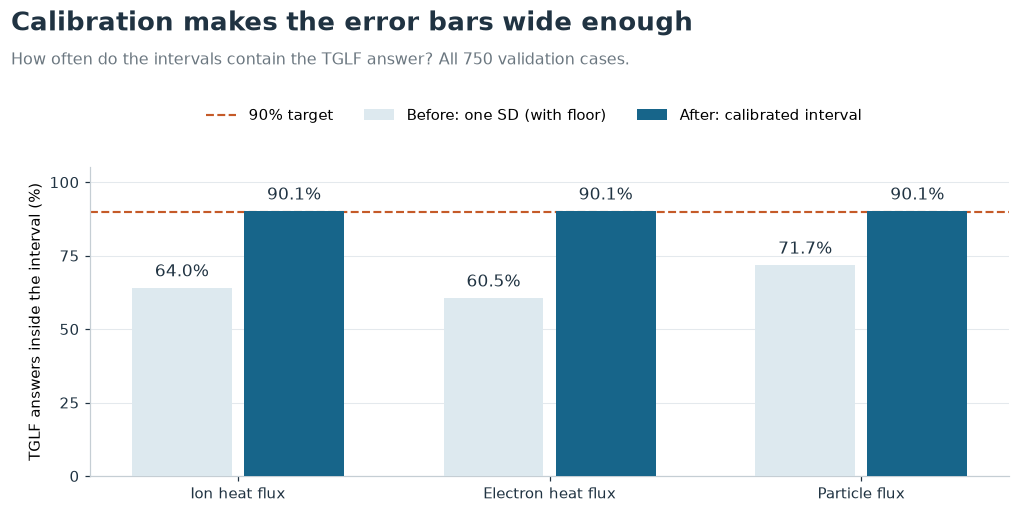

**Figure 1. Calibration widens intervals to match observed errors.** Before calibration, one floor-adjusted SD covers 64.0%, 60.5%, and 71.7% of validation answers. After calibration, coverage is about **90%** for each flux. These are the cases used to choose the widths; the next figure checks separate test cases.

,SD floor,Interval multiplier
Q_i,0.884,2.553
Q_e,0.726,2.528
Gamma_e,0.253,2.038


[Back to contents](#contents)

In [2]:
validation_x = workflow.features.loc[workflow.ids["validation"]]
validation_y = workflow.truth("validation")
validation = workflow.predict(validation_x, members)
calibration = calibrate(validation, validation_y, workflow.training_scale,
                        alpha=ALPHA, floor_fraction=0.01)

fig, caption = calibration_figure(validation, validation_y, calibration, output_dir=FIGURES)
plt.show()
display(Markdown(caption))
show_details("Calibration settings", pd.DataFrame({
    "SD floor": calibration["floor"], "Interval multiplier": calibration["scaled_multiplier"]},
    index=TARGETS))
display(Markdown("[Back to contents](#contents)"))

<a id="step-2"></a>
## Step 2: Check the error bars on the test set

**Do the TGLF answers fall inside our 90% prediction intervals?**

- **Blue line:** the average prediction from all 15 networks.
- **Blue band:** the calibrated 90% prediction interval around that prediction.
- **Orange dots:** the actual TGLF answers. A dot outside the band is a miss.

To keep the figure readable, show a fixed random sample of **50 test cases**, with
the same cases in every panel. Each panel orders those cases from lowest to highest
predicted flux; this is not time or a scan of one plasma input. All selected values
and interval bounds are shown, including negative values. Change `PLOT_CASES` in
Setup to display more cases.

The coverage percentages use **all 750 test cases**, not just the plotted sample.
The target is roughly nine answers inside the interval for every ten cases.
Wider intervals can cover more answers, so read coverage alongside interval width.

The expandable tables retain the other assignment checks: whether larger uncertainty
accompanies larger errors, and which input region has the greatest uncertainty.
**MAE** is the average size of a miss; **RMSE** gives larger misses more weight.
**Spearman** measures agreement between the rankings of uncertainty and error.


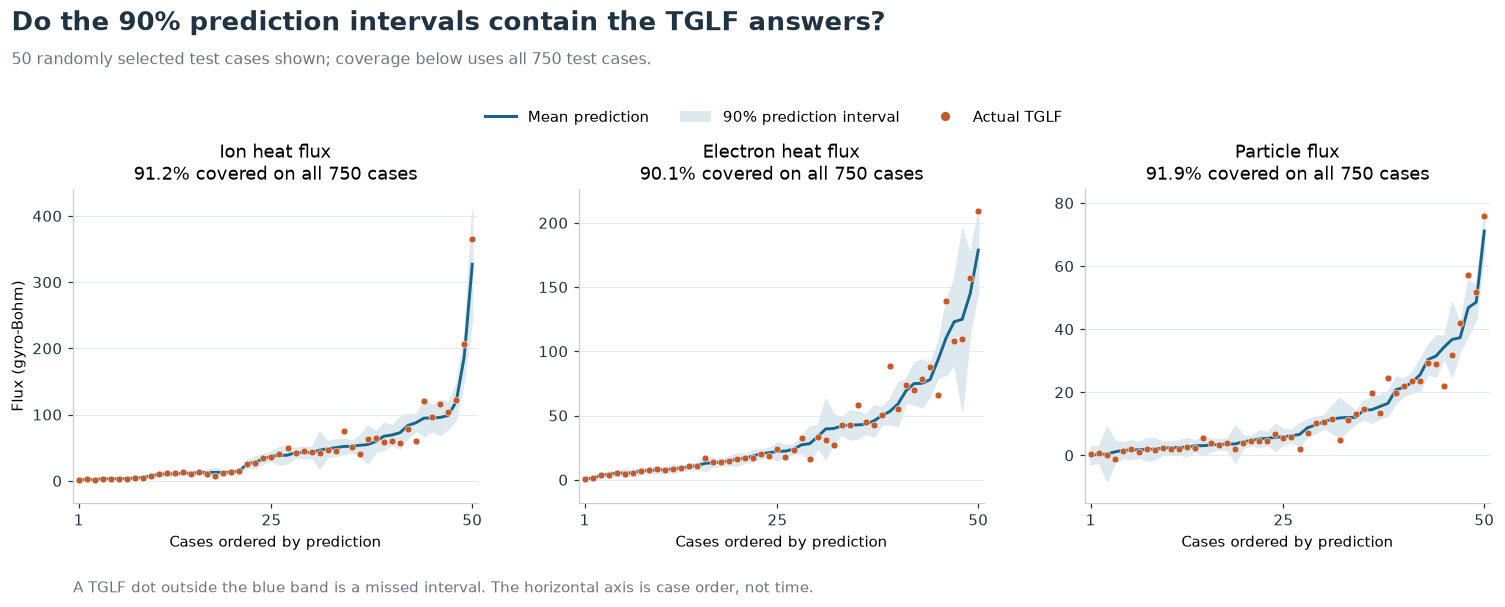

**Figure 2. Predictions with 90% prediction intervals.** The blue line is the 15-network mean, the shaded band is the calibrated interval, and each orange dot is a TGLF answer. A dot outside the band is a miss. Across the **full test set**, coverage is **91.2%, 90.1%, and 91.9%**. For readability, all panels show the same 50 cases sampled without replacement using seed 2026, sorted separately by each flux's prediction. The connected line and band only guide the eye between separate cases. Bounds remain unclipped, including negative bounds.

,mae,rmse,coverage,mean_width,Spearman
target,,,,,
Q_i,6.793,15.674,0.912,30.110,0.708
Q_e,5.406,11.742,0.901,23.290,0.684
Gamma_e,1.730,3.384,0.919,7.163,0.526


,feature,range,target,n,mean_std,mae,coverage
104,log10_XNUE,"(-1.999, -1.501]",Gamma_e,188,2.458,2.915,0.856
103,log10_XNUE,"(-1.999, -1.501]",Q_e,188,9.037,10.226,0.867
102,log10_XNUE,"(-1.999, -1.501]",Q_i,188,11.074,12.333,0.862


The lowest-collisionality group has the greatest average uncertainty for all three fluxes. Its coverage is about 86%, below the overall test result. Good overall coverage does not guarantee good coverage in every input region.

[Back to contents](#contents)

In [3]:
test_x = workflow.features.loc[workflow.ids["test"]]
test_y = workflow.truth("test")
test = workflow.predict(test_x, members)
test_predictions = prediction_frame(test, calibration, test_y)
test_metrics = metrics(test, test_y, calibration, "test").set_index("target")
regions = region_summary(test_x, test, test_y, calibration)
most_uncertain = regions.loc[regions.groupby("target").mean_std.idxmax()]

fig, caption = test_figure(test, test_y, calibration, test_metrics,
                          output_dir=FIGURES, sample_size=PLOT_CASES, seed=RANDOM_SEED)
plt.show()
display(Markdown(caption))
show_details("Accuracy, coverage, and interval width: all 750 test cases",
             test_metrics[["mae", "rmse", "coverage", "mean_width", "error_uncertainty_spearman"]]
             .rename(columns={"error_uncertainty_spearman": "Spearman"}))
show_details("Input region with the largest average uncertainty for each flux", most_uncertain)
display(Markdown("The lowest-collisionality group has the greatest average uncertainty for all three "
                 "fluxes. Its coverage is about 86%, below the overall test result. "
                 "Good overall coverage does not guarantee good coverage in every input region."
                 "\n\n[Back to contents](#contents)"))

<a id="step-3"></a>
## Step 3: Predict outside the training range

**Do the intervals still cover about 90% of the answers for unfamiliar inputs?**

Test **nine sets of 30 cases**, with one input outside its training range in each
set. Keep the same 15 networks and calibration. Each dot shows a group's coverage;
the dashed line is the 90% target. Orange dots fall short of that target.

The expandable table also compares prediction error and network disagreement with
the ordinary test set. A ratio of 2 means twice as large. If error grows while
network disagreement stays small, agreement is giving us false reassurance.


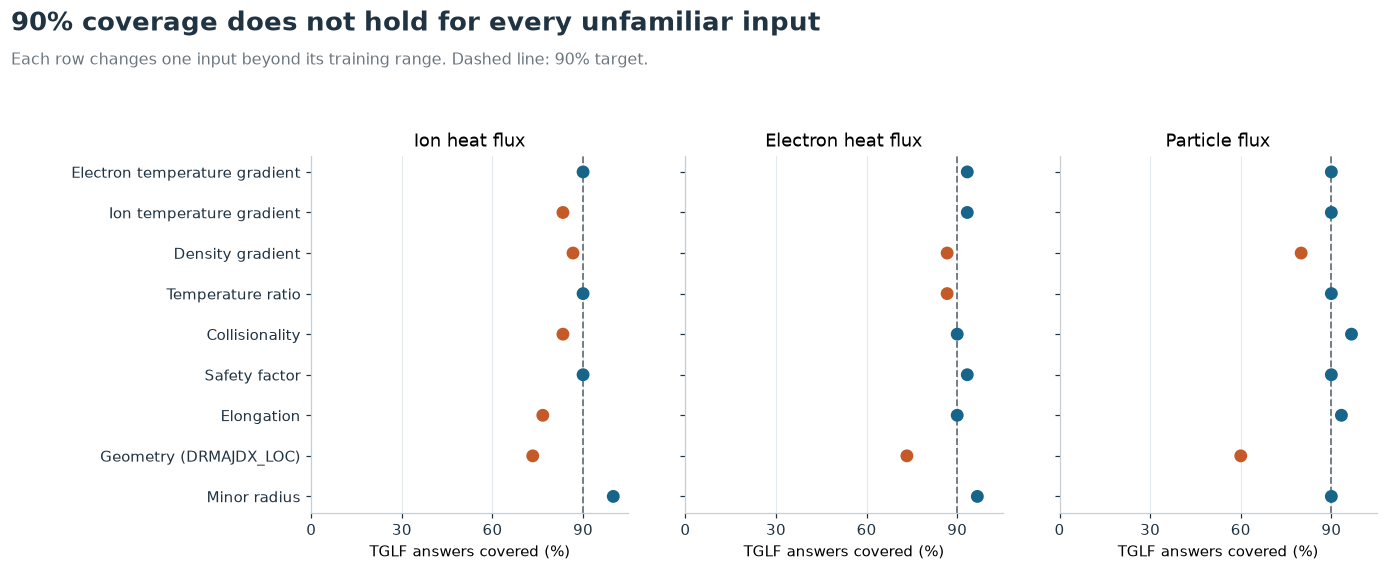

**Figure 3. Check coverage when an input leaves the training range.** Orange dots fall below the 90% target. The lowest coverage is **60% for particle flux** in the **Geometry (DRMAJDX_LOC)** group. Treat these predictions with caution. Each dot uses only 30 cases, so one additional miss changes coverage by 3.3 percentage points. Error and disagreement comparisons are available below.

For outside-range collisionality, ion heat-flux error grows to **1.32×** the test-set error, while network disagreement falls to **0.34×**. Agreement alone does not establish accuracy.

[Back to contents](#contents)

In [4]:
reports = []
for name in OOD_SETS:
    _, x, y = workflow.load_external(DATA_DIR / "scan_db_outside" / name / "data", expected_count=30)
    predicted = workflow.predict(x, members)
    reports.append(metrics(predicted, y, calibration, name))
ood_metrics = pd.concat(reports, ignore_index=True)
ood_metrics["RMSE ratio"] = ood_metrics.rmse / ood_metrics.target.map(test_metrics.rmse)
ood_metrics["SD ratio"] = ood_metrics.mean_std / ood_metrics.target.map(test_metrics.mean_std)
ood_metrics["Coverage (%)"] = 100 * ood_metrics.coverage

fig, caption = ood_figure(ood_metrics, output_dir=FIGURES)
plt.show()
display(Markdown(caption))
show_details("Error, disagreement, and coverage for all nine input groups",
             ood_metrics.set_index(["dataset", "target"])[["RMSE ratio", "SD ratio", "Coverage (%)"]])
xnue_ion = ood_metrics.loc[ood_metrics.dataset.eq("ood_XNUE") & ood_metrics.target.eq("Q_i")].iloc[0]
display(Markdown(f"For outside-range collisionality, ion heat-flux error grows to "
                 f"**{xnue_ion['RMSE ratio']:.2f}×** the test-set error, while network disagreement falls "
                 f"to **{xnue_ion['SD ratio']:.2f}×**. Agreement alone does not establish accuracy."
                 "\n\n[Back to contents](#contents)"))

<a id="step-4"></a>
## Step 4: Forward uncertainty quantification

Here we ask a different question: **if the measured plasma inputs are a little
wrong, how much could the predicted fluxes change?** Keep the model fixed and
create 10,000 plausible versions of the DIII-D reference case by varying its inputs.
These are prediction cases; we do not train on them.

Sample independently and uniformly within the handout's error bars: ±10% for
both temperature gradients, the shared density gradient, temperature ratio, and
`Q_PRIME_LOC`; ±20% for `XNUE`; and ±5% for `Q_LOC`. Keep `RLNS_1 = RLNS_2` and all
other inputs fixed. Uniform sampling gives every value within a range equal density.

Run each input set through the ensemble and collect the mean predictions.
Their distribution shows how input uncertainty spreads into output uncertainty:

- **Mean:** the average predicted flux across the input draws.
- **SD:** how much those fluxes vary as the inputs change.
- **q05 and q95:** the boundaries containing the middle 90% of the sampled flux values.

This spread describes variation caused by the inputs. Step 1's error bars describe
uncertainty in the model's prediction at a given input.

Compare with the **300 supplied TGLF runs**. We also predict those exact 300 inputs,
so differences in that comparison come from surrogate errors rather than different
random input samples. In the histograms, compare the location, width, and shape of
the two curves. Similar averages alone do not establish a distribution match.

The plot focuses on the two output distributions. The expandable table below it
reports means, SDs, and middle 90% ranges, including the comparison at matched inputs.
Those ranges describe the flux distribution, not Step 1's prediction intervals.

In [5]:
reference_table, _, _ = workflow.load_external(DATA_DIR / "data_d3d/d3d_db", expected_count=1)
input_columns = list(INPUT_FRACTIONS) + ["RLNS_2", "KAPPA_LOC", "DRMAJDX_LOC", "RMIN_LOC", "MASS_2"]
reference = reference_table.iloc[0][input_columns].astype(float)
_, uq_x, uq_y = workflow.load_external(DATA_DIR / "data_d3d/d3d_uq/data", expected_count=300)
paired = workflow.predict(uq_x, members)

started = time.perf_counter()
mc_inputs = sample_inputs(reference, n=MC_CASES, seed=RANDOM_SEED)
mc_x = engineer_features(mc_inputs, workflow.columns)
inference_started = time.perf_counter()
mc_prediction = workflow.predict(mc_x, members)
inference_seconds = time.perf_counter() - inference_started
total_seconds = time.perf_counter() - started
print(f"10,000 cases, all 15 networks: {inference_seconds:.3f} s inference; "
      f"{total_seconds:.3f} s including sampling and features (CPU, 4 threads).")

distribution = pd.concat([
    distribution_summary(mc_prediction["mean"], "Surrogate: 10,000 draws"),
    distribution_summary(paired["mean"], "Surrogate: paired 300"),
    distribution_summary(uq_y.to_numpy(), "TGLF: same 300"),
], ignore_index=True)

10,000 cases, all 15 networks: 0.045 s inference; 0.051 s including sampling and features (CPU, 4 threads).


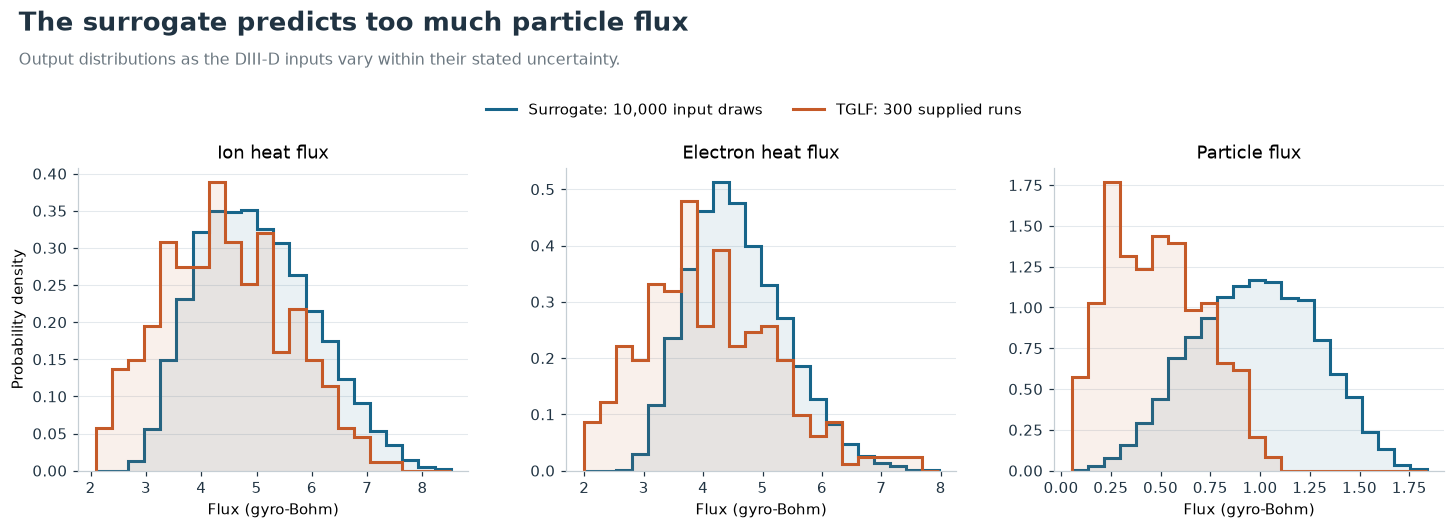

**Figure 4. Compare the location, width, and shape of the distributions.** The particle-flux predictions are shifted above TGLF. On the exact same 300 inputs, the surrogate's mean is **+106%** above TGLF for particle flux (ion heat: +11.4%; electron heat: +11.8%). This spread comes from varying the inputs; it is different from the prediction intervals in Figure 2.

[Back to contents](#contents)

In [6]:
fig, caption = forward_figure(mc_prediction, paired, uq_y, output_dir=FIGURES)
plt.show()
display(Markdown(caption))
show_details("Distribution statistics, including the same 300 inputs",
             distribution.set_index(["target", "source"])[["mean", "std", "q05", "q95"]]
             .reindex(TARGETS, level="target"))
display(Markdown("[Back to contents](#contents)"))

<a id="step-4b"></a>
### Step 4b: Which input matters most?

Repeat the experiment while varying **only one input at a time** and holding all
others at the reference value. Treat the two equal density gradients as one shared
input. Use the same uncertainty ranges and random seed as Step 4.

A longer bar means that input's stated measurement uncertainty produces more
variation in the predicted flux. **Orange marks the largest effect** for each flux.
These are local sensitivity estimates from the surrogate, not fractions of total
uncertainty. The exact SDs are in the expandable table.


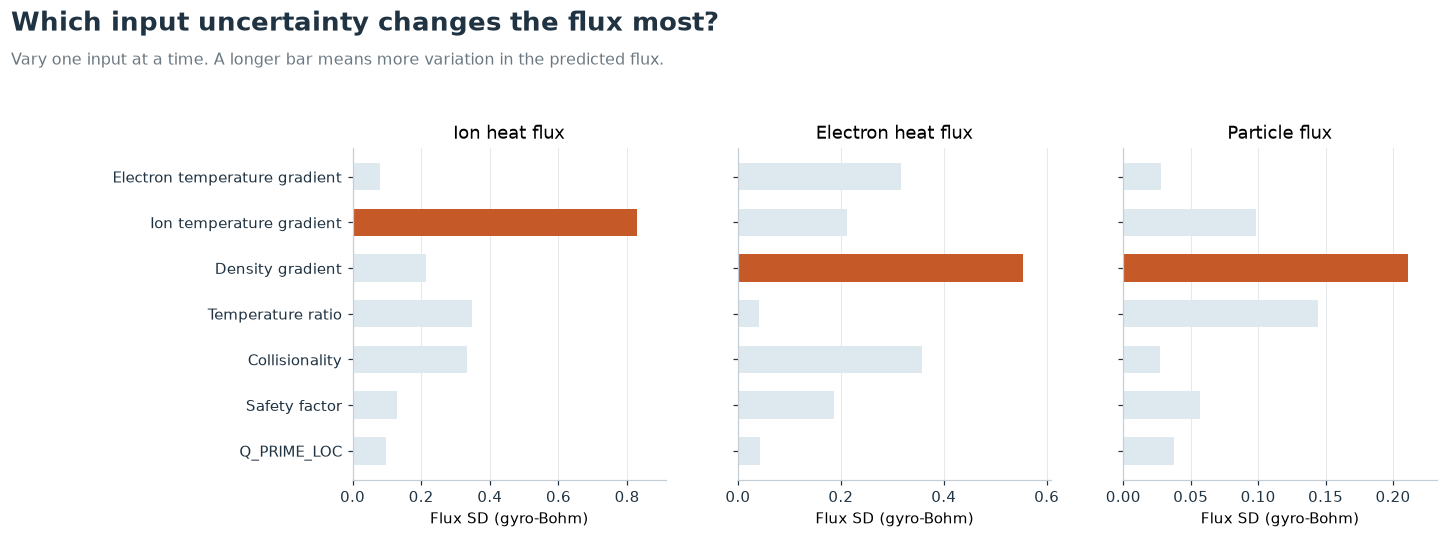

**Figure 5. Orange marks the largest effect.** Ion heat flux responds most to the **ion temperature gradient**; electron heat and particle flux both respond most to the **density gradient**. These priorities apply to the supplied measurement error bars near this reference case, according to the surrogate. The bars are not additive shares of total uncertainty, and the TGLF mismatch in Figure 4 limits their interpretation.

target,Q_i,Q_e,Gamma_e
input,,,
RLTS_1,0.081,0.316,0.028
RLTS_2,0.830,0.211,0.098
RLNS_1,0.214,0.553,0.211
TAUS_2,0.347,0.041,0.145
XNUE,0.335,0.357,0.027
Q_LOC,0.129,0.187,0.057
Q_PRIME_LOC,0.097,0.042,0.037


[Back to contents](#contents)

In [7]:
sensitivity_rows = []
for input_name in INPUT_FRACTIONS:
    draws = sample_inputs(reference, n=MC_CASES, seed=RANDOM_SEED, varying=[input_name])
    predicted = workflow.predict(engineer_features(draws, workflow.columns), members)
    sensitivity_rows.append(distribution_summary(predicted["mean"], input_name))
sensitivity = pd.concat(sensitivity_rows, ignore_index=True).rename(columns={"source": "input"})


fig, caption = sensitivity_figure(sensitivity, output_dir=FIGURES)
plt.show()
display(Markdown(caption))
show_details("Flux SD when each input varies alone",
             sensitivity.pivot(index="input", columns="target", values="std").loc[list(INPUT_FRACTIONS), TARGETS])
display(Markdown("[Back to contents](#contents)"))

<a id="mentor-discussion"></a>
## Findings to discuss with our mentors

**The intervals are useful on the ordinary test set, but coverage alone can hide a biased surrogate.**

| Finding | Evidence | What it means |
|---|---|---|
| The uncertainty estimate adds useful information. | Test coverage is 91.2%, 90.1%, and 91.9%. Compared with validation-calibrated constant-width intervals, average widths are 22% smaller for electron heat and 25% smaller for particle flux, with similar coverage. | Varying the interval width by case gives more precise intervals on average than assigning every case the same error bar. |
| Network agreement does not reliably flag unfamiliar conditions. | In the outside-range collisionality group, ion-heat RMSE is 1.32 times the ordinary test value while network SD is only 0.34 times as large. Particle-flux coverage falls to 60% (18/30) in the outside-range geometry group. | A known input-range violation deserves an explicit warning, even if the networks agree. |
| Broad intervals can conceal a consistent local bias. | In the DIII-D comparison, particle flux is overpredicted in **300/300 cases**. Its mean is **0.995 versus TGLF's 0.483**, a bias of **+0.512 gyro-Bohm (+106%)**. Yet interval coverage is **100%**, with an average width of **3.85 gyro-Bohm**. | Covering the answer is not enough: the center and width must also be useful for the intended physics calculation. |

**The next investigation should focus on the DIII-D particle-flux bias.** Check the nearby training examples, error at low particle-flux magnitudes, and individual network predictions. Those checks can distinguish poor local training coverage from a fitting or target-scaling issue. These are candidate explanations; we have not established the cause. Any model changes should be chosen using validation data and evaluated on fresh held-out cases.

Questions for Jeff and Emily:

- Is a particle-flux bias of about **0.51 gyro-Bohm** consequential for the intended transport calculation? What absolute error and interval width would be useful?
- The surrogate is most sensitive to the **ion temperature gradient** for ion heat flux and the **density gradient** for electron heat and particle flux. Is this plausible near the supplied DIII-D reference case, and which scan would best test it with TGLF?
- Should we prioritize accuracy near this DIII-D regime, or broader reliability across the full sampled parameter range?

These are empirical findings from the current split. Validation data were reused from A2, each unfamiliar-input group has only 30 cases, and the sensitivity rankings describe this surrogate near one reference case with the supplied input uncertainties.

[Back to contents](#contents)
